# MLP Neural Network — Credit Card Default Prediction

This notebook builds a multilayer perceptron (MLP) **from scratch in NumPy**: the forward pass, backpropagation, and mini-batch gradient descent are all written by hand. No modeling packages are used to build or train the network. scikit-learn is only used to *score* the predictions (accuracy, ROC-AUC, etc.).

It uses the exact same train/test split as the Bayesian logistic regression notebook, so the two models can be compared fairly.

In [1]:
import os
print("Notebook is running in:", os.getcwd())
print("data/processed exists:", os.path.exists("../data/processed"))
if os.path.exists("../data/processed"):
    print("Files in it:", os.listdir("../data/processed"))

Notebook is running in: /Users/ansha1/ds4420-credit-default/notebooks
data/processed exists: True
Files in it: ['bayes_test_probs.csv', '.gitkeep', 'X_train.csv', 'y_train.csv', 'y_test.csv', 'X_test.csv']


In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix, ConfusionMatrixDisplay)

SEED = 42
np.random.seed(SEED)

DATA_DIR = "../data/processed/"
FIG_DIR = "../figures/"
os.makedirs(FIG_DIR, exist_ok=True)

In [3]:
def load_csv(name):
    df = pd.read_csv(DATA_DIR + name)
    # If the file was saved with its index, pandas reads it back as an extra "Unnamed: 0" column. Drop it.
    df = df.loc[:, ~df.columns.astype(str).str.startswith("Unnamed")]
    return df

X_train_df = load_csv("X_train.csv")
X_test_df = load_csv("X_test.csv")
y_train = load_csv("y_train.csv").values.ravel().astype(int)
y_test = load_csv("y_test.csv").values.ravel().astype(int)

feature_names = list(X_train_df.columns)
X_train = X_train_df.values.astype(float)
X_test = X_test_df.values.astype(float)

print("Train:", X_train.shape, "| Test:", X_test.shape)
print(f"Default rate — train: {y_train.mean():.3f}, test: {y_test.mean():.3f}")
print(f"Baseline accuracy (always predict 'no default') on test: {1 - y_test.mean():.4f}")

Train: (24000, 82) | Test: (6000, 82)
Default rate — train: 0.221, test: 0.221
Baseline accuracy (always predict 'no default') on test: 0.7788


## 2. Standardize the features

Neural networks train much better when every feature is on a similar scale. We compute the mean and standard deviation from the **training set only** and apply them to both sets, so no information from the test set leaks in. The continuous columns were already standardized in the preprocessing notebook, so this step leaves them unchanged.

The one-hot (0/1) columns are left as they are. Some categories are very rare (a handful of customers out of 24,000), and standardizing those would turn their 1s into huge numbers that make training unstable.

In [4]:
# A column is "binary" if it only contains 0s and 1s (the one-hot columns). Those keep their original values.
is_binary = np.all(np.isin(X_train, [0, 1]), axis=0)
mu = np.where(is_binary, 0.0, X_train.mean(axis=0))
sigma = np.where(is_binary, 1.0, X_train.std(axis=0))
sigma[sigma == 0] = 1.0   # avoid dividing by zero for any constant column
print(f"{(~is_binary).sum()} continuous columns standardized, {is_binary.sum()} one-hot columns left as 0/1")

X_train_s = (X_train - mu) / sigma
X_test_s = (X_test - mu) / sigma

14 continuous columns standardized, 68 one-hot columns left as 0/1


## 3. Hold out a validation set from the training data

We set aside 15% of the training rows (keeping the same default rate) to decide when to stop training. The test set is never touched until the very end.

In [5]:
def stratified_split(y, val_frac, seed):
    rng = np.random.default_rng(seed)
    val_idx = []
    for cls in np.unique(y):
        idx = np.where(y == cls)[0]
        rng.shuffle(idx)
        val_idx.extend(idx[: int(len(idx) * val_frac)])
    val_idx = np.array(sorted(val_idx))
    tr_idx = np.setdiff1d(np.arange(len(y)), val_idx)
    return tr_idx, val_idx

tr_idx, val_idx = stratified_split(y_train, val_frac=0.15, seed=SEED)
X_tr, y_tr = X_train_s[tr_idx], y_train[tr_idx]
X_val, y_val = X_train_s[val_idx], y_train[val_idx]
print("Fitting rows:", len(y_tr), "| Validation rows:", len(y_val))

Fitting rows: 20401 | Validation rows: 3599


## 4. The MLP, written by hand

**Structure:** input features → hidden layers with ReLU activation → one output unit with a sigmoid, which gives the predicted probability of default.

**Loss:** binary cross-entropy (the same loss as logistic regression), plus a small L2 penalty on the weights to discourage overfitting.

**Training:** backpropagation computes the gradient of the loss with respect to every weight, and mini-batch gradient descent updates the weights a small step at a time.

A useful way to think about it: logistic regression is an MLP with zero hidden layers. The hidden layers let the model learn combinations of features that a straight linear model can't.

`pos_weight` lets the loss count defaulters more heavily, which can raise recall. It is set to 1 (no reweighting) so the results compare directly with the Bayesian model.

In [6]:
def sigmoid(z):
    return 1.0 / (1.0 + np.exp(-np.clip(z, -500, 500)))


class MLP:
    def __init__(self, layer_sizes, l2=1e-4, pos_weight=1.0, seed=42):
        # layer_sizes example: [n_features, 32, 16, 1]
        rng = np.random.default_rng(seed)
        self.W, self.b = [], []
        for n_in, n_out in zip(layer_sizes[:-1], layer_sizes[1:]):
            # He initialization: random weights scaled to suit ReLU layers
            self.W.append(rng.normal(0.0, np.sqrt(2.0 / n_in), size=(n_in, n_out)))
            self.b.append(np.zeros(n_out))
        self.l2 = l2
        self.pos_weight = pos_weight

    def forward(self, X):
        # Returns each layer's pre-activation values (z) and activations (a), which backprop needs
        zs, activations = [], [X]
        a = X
        n_layers = len(self.W)
        for i in range(n_layers):
            z = a @ self.W[i] + self.b[i]
            zs.append(z)
            a = sigmoid(z) if i == n_layers - 1 else np.maximum(0.0, z)  # ReLU for hidden, sigmoid for output
            activations.append(a)
        return zs, activations

    def predict_proba(self, X):
        return self.forward(X)[1][-1].ravel()

    def loss(self, X, y):
        p = np.clip(self.predict_proba(X), 1e-12, 1 - 1e-12)
        w = np.where(y == 1, self.pos_weight, 1.0)
        bce = -np.mean(w * (y * np.log(p) + (1 - y) * np.log(1 - p)))
        penalty = 0.5 * self.l2 * sum(np.sum(W ** 2) for W in self.W)
        return bce + penalty

    def gradients(self, X, y):
        zs, acts = self.forward(X)
        n = X.shape[0]
        p = acts[-1].ravel()
        w = np.where(y == 1, self.pos_weight, 1.0)

        # With a sigmoid output and cross-entropy loss, the error at the output simplifies to (p - y)
        delta = (w * (p - y) / n).reshape(-1, 1)

        grads_W = [None] * len(self.W)
        grads_b = [None] * len(self.W)
        for i in reversed(range(len(self.W))):
            grads_W[i] = acts[i].T @ delta + self.l2 * self.W[i]
            grads_b[i] = delta.sum(axis=0)
            if i > 0:
                # Pass the error back through the weights, then through the ReLU (gradient is 1 where z > 0, else 0)
                delta = (delta @ self.W[i].T) * (zs[i - 1] > 0)
        return grads_W, grads_b

## 5. Check that backpropagation is correct

Because the gradients are written by hand, we verify them against a numerical estimate: nudge a weight up and down by a tiny amount and see how much the loss changes. If backprop is right, the two numbers should match almost exactly (relative difference around 1e-7 or smaller).

In [7]:
def gradient_check(n_checks=10, eps=1e-5):
    rng = np.random.default_rng(0)
    Xc = rng.normal(size=(20, 5))
    yc = rng.integers(0, 2, size=20)
    m = MLP([5, 4, 3, 1], l2=1e-3, seed=1)
    gW, _ = m.gradients(Xc, yc)
    worst = 0.0
    for _ in range(n_checks):
        layer = rng.integers(len(m.W))
        i, j = rng.integers(m.W[layer].shape[0]), rng.integers(m.W[layer].shape[1])
        orig = m.W[layer][i, j]
        m.W[layer][i, j] = orig + eps; up = m.loss(Xc, yc)
        m.W[layer][i, j] = orig - eps; down = m.loss(Xc, yc)
        m.W[layer][i, j] = orig
        numeric = (up - down) / (2 * eps)
        analytic = gW[layer][i, j]
        rel = abs(numeric - analytic) / max(1e-12, abs(numeric) + abs(analytic))
        worst = max(worst, rel)
    print(f"Largest relative difference: {worst:.2e}", "-> backprop looks correct" if worst < 1e-5 else "-> CHECK BACKPROP")

gradient_check()

Largest relative difference: 9.89e-09 -> backprop looks correct


## 6. Train with mini-batch gradient descent and early stopping

Each epoch shuffles the fitting rows, splits them into small batches, and takes one gradient step per batch. After every epoch we record the loss on the fitting rows and on the validation rows. If the validation loss hasn't improved for `patience` epochs, we stop and go back to the best weights we saw. This keeps the network from memorizing the training data.

In [8]:
def train(model, X_tr, y_tr, X_val, y_val, lr=0.05, batch_size=128, epochs=300, patience=20, seed=42):
    rng = np.random.default_rng(seed)
    history = {"train_loss": [], "val_loss": []}
    best_val, best_epoch, wait = np.inf, 0, 0
    best_W = [W.copy() for W in model.W]
    best_b = [b.copy() for b in model.b]

    for epoch in range(1, epochs + 1):
        order = rng.permutation(len(y_tr))
        for start in range(0, len(order), batch_size):
            batch = order[start:start + batch_size]
            gW, gb = model.gradients(X_tr[batch], y_tr[batch])
            for i in range(len(model.W)):
                model.W[i] -= lr * gW[i]
                model.b[i] -= lr * gb[i]

        tr_loss, val_loss = model.loss(X_tr, y_tr), model.loss(X_val, y_val)
        history["train_loss"].append(tr_loss)
        history["val_loss"].append(val_loss)

        if val_loss < best_val - 1e-5:
            best_val, best_epoch, wait = val_loss, epoch, 0
            best_W = [W.copy() for W in model.W]
            best_b = [b.copy() for b in model.b]
        else:
            wait += 1
            if wait >= patience:
                print(f"Early stopping at epoch {epoch}.")
                break

    model.W, model.b = best_W, best_b
    print(f"Best validation loss {best_val:.4f} at epoch {best_epoch}.")
    return history, best_epoch


n_features = X_tr.shape[1]
mlp = MLP([n_features, 32, 16, 1], l2=1e-4, pos_weight=1.0, seed=SEED)
history, best_epoch = train(mlp, X_tr, y_tr, X_val, y_val,
                            lr=0.05, batch_size=128, epochs=300, patience=20, seed=SEED)

Early stopping at epoch 82.
Best validation loss 0.4277 at epoch 62.


## 7. Training curve (Figure for the report)

The two lines should drop and then level off. If the validation line starts rising while the training line keeps falling, the network is starting to overfit; the dashed line marks the epoch whose weights we kept.

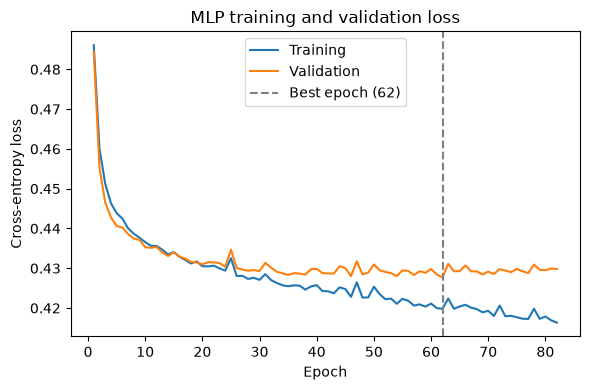

In [9]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(range(1, len(history["train_loss"]) + 1), history["train_loss"], label="Training")
ax.plot(range(1, len(history["val_loss"]) + 1), history["val_loss"], label="Validation")
ax.axvline(best_epoch, linestyle="--", color="gray", label=f"Best epoch ({best_epoch})")
ax.set_xlabel("Epoch")
ax.set_ylabel("Cross-entropy loss")
ax.set_title("MLP training and validation loss")
ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR + "mlp_loss_curve.png", dpi=200)
plt.show()

## 8. Evaluate on the test set

Same metrics as the Bayesian model, using a 0.5 cutoff: anyone with a predicted default probability of 50% or more is labeled a defaulter.

In [10]:
test_probs = mlp.predict_proba(X_test_s)
test_preds = (test_probs >= 0.5).astype(int)

mlp_metrics = {
    "Accuracy": accuracy_score(y_test, test_preds),
    "Precision": precision_score(y_test, test_preds, zero_division=0),
    "Recall": recall_score(y_test, test_preds),
    "F1 Score": f1_score(y_test, test_preds),
    "ROC-AUC": roc_auc_score(y_test, test_probs),
}
for name, value in mlp_metrics.items():
    print(f"{name}: {value * 100:.2f}%")

# Save the test probabilities so they can be plotted next to the Bayesian model's
pd.DataFrame({"mlp_prob": test_probs}).to_csv(DATA_DIR + "mlp_test_probs.csv", index=False)

Accuracy: 81.70%
Precision: 65.25%
Recall: 36.93%
F1 Score: 47.16%
ROC-AUC: 76.87%


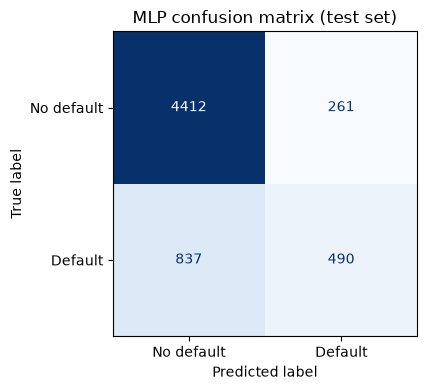

In [11]:
cm = confusion_matrix(y_test, test_preds)
fig, ax = plt.subplots(figsize=(4.5, 4))
ConfusionMatrixDisplay(cm, display_labels=["No default", "Default"]).plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title("MLP confusion matrix (test set)")
fig.tight_layout()
fig.savefig(FIG_DIR + "mlp_confusion_matrix.png", dpi=200)
plt.show()

## 9. Compare with the Bayesian model (Table for the report)

The Bayesian numbers below are the ones from the Bayesian notebook. Update them if that notebook is re-run.

In [12]:
bayes_metrics = {
    "Accuracy": 0.8172,
    "Precision": 0.6624,
    "Recall": 0.3534,
    "F1 Score": 0.4609,
    "ROC-AUC": 0.7622,
}

comparison = pd.DataFrame({
    "Bayesian Logistic Regression": bayes_metrics,
    "MLP Neural Network": mlp_metrics,
}).mul(100).round(2)
comparison.loc["Baseline accuracy (always 'no default')"] = [round((1 - y_test.mean()) * 100, 2)] * 2
comparison.to_csv(FIG_DIR + "model_comparison.csv")
comparison

,Bayesian Logistic Regression,MLP Neural Network
Accuracy,81.72,81.70
Precision,66.24,65.25
Recall,35.34,36.93
F1 Score,46.09,47.16
ROC-AUC,76.22,76.87
Baseline accuracy (always 'no default'),77.88,77.88


## 10. ROC curves for both models on one plot

This needs the Bayesian notebook to save its test-set probabilities as `bayes_test_probs.csv` in `data/processed/` (one column of predicted default probabilities, in the same row order as `X_test.csv`). If that file isn't there yet, only the MLP curve is drawn.

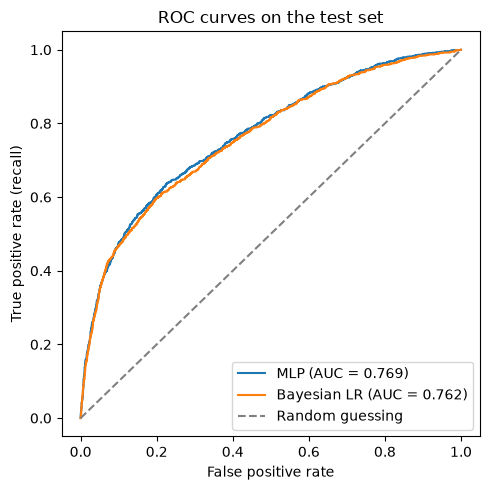

In [13]:
fig, ax = plt.subplots(figsize=(5, 5))
fpr, tpr, _ = roc_curve(y_test, test_probs)
ax.plot(fpr, tpr, label=f"MLP (AUC = {mlp_metrics['ROC-AUC']:.3f})")

bayes_path = DATA_DIR + "bayes_test_probs.csv"
if os.path.exists(bayes_path):
    bayes_probs = load_csv("bayes_test_probs.csv").values.ravel()
    fpr_b, tpr_b, _ = roc_curve(y_test, bayes_probs)
    ax.plot(fpr_b, tpr_b, label=f"Bayesian LR (AUC = {roc_auc_score(y_test, bayes_probs):.3f})")
else:
    print("bayes_test_probs.csv not found — plotting the MLP only.")

ax.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Random guessing")
ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate (recall)")
ax.set_title("ROC curves on the test set")
ax.legend(loc="lower right")
fig.tight_layout()
fig.savefig(FIG_DIR + "roc_comparison.png", dpi=200)
plt.show()